# Đánh Giá So Sánh Các Mô Hình Dự Báo Cổ Phiếu FPT

So sánh 4 mô hình trên cùng tập kiểm thử độc lập (20% dữ liệu gần nhất):
Naive Baseline, Hồi quy tuyến tính, XGBoost và LSTM.

Tiêu chí đánh giá:
1. Hit Rate (%): tỷ lệ dự đoán đúng chiều tăng hoặc giảm của phiên kế tiếp (trên 50% là có lợi thế thống kê).
2. RMSE: sai số căn bậc hai trung bình bình phương, phạt nặng các sai số lớn.
3. MAE: sai số tuyệt đối trung bình.

## 1. Thiết lập môi trường

In [1]:
import os
import joblib
import numpy as np
import pandas as pd
from pathlib import Path

BASE_DIR = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
TICKER = 'FPT.VN'
DATA_PATH = BASE_DIR / 'data' / 'interim' / f'{TICKER}_features.csv'
BASELINES_DIR = BASE_DIR / 'models' / 'baselines'
DL_DIR = BASE_DIR / 'models' / 'deep_learning' / 'fpt'
FIG_DIR = BASE_DIR / 'reports' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)
DL_DIR.mkdir(parents=True, exist_ok=True)
print('Mã cổ phiếu:', TICKER)
print('Dữ liệu:', DATA_PATH, '| tồn tại:', DATA_PATH.exists())

import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.metrics import mean_squared_error, mean_absolute_error

Mã cổ phiếu: FPT.VN
Dữ liệu: d:\Dev\Subject_Uni\Machine_Learning\Stock_Prediction_Project\data\interim\FPT.VN_features.csv | tồn tại: True


## 2. Chuẩn bị dữ liệu kiểm thử và nạp mô hình

In [2]:
LOOKBACK = 60
df = pd.read_csv(DATA_PATH)
df['Target_Return'] = df['Log_Return'].shift(-1)
df.replace([np.inf, -np.inf], np.nan, inplace=True)
df.dropna(inplace=True)
df.reset_index(drop=True, inplace=True)

feature_cols = [c for c in df.columns if c not in ['Date', 'Target_Return']]
X, y = df[feature_cols], df['Target_Return']

test_size = int(len(df) * 0.20)
X_test = X.iloc[-test_size:].reset_index(drop=True)
y_test = y.iloc[-test_size:].reset_index(drop=True)
idx = list(range(LOOKBACK, len(X_test)))
y_eval = y_test.iloc[idx].values
print('Số phiên kiểm thử:', len(y_eval))

lr_model = joblib.load(BASELINES_DIR / f'{TICKER}_lr_baseline.pkl')
xgb_model = joblib.load(BASELINES_DIR / f'{TICKER}_xgb_baseline.pkl')
lstm_model = tf.keras.models.load_model(DL_DIR / f'{TICKER}_lstm_model.keras')
f_scaler = joblib.load(DL_DIR / f'{TICKER}_feature_scaler.pkl')
t_scaler = joblib.load(DL_DIR / f'{TICKER}_target_scaler.pkl')

Số phiên kiểm thử: 316


d:\Dev\Subject_Uni\Machine_Learning\Stock_Prediction_Project\venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator MinMaxScaler from version 1.6.1 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


## 3. Dự báo và tính các chỉ số

In [3]:
X_seq = np.array([f_scaler.transform(X_test.values)[i - LOOKBACK:i] for i in idx])
predictions = {
    'Naive Baseline': X_test['Log_Return'].values[idx],
    'Hồi quy tuyến tính': lr_model.predict(X_test.iloc[idx]),
    'XGBoost': xgb_model.predict(X_test.iloc[idx]),
    'LSTM': t_scaler.inverse_transform(lstm_model.predict(X_seq, verbose=0)).flatten(),
}

rows = []
for name, pred in predictions.items():
    t, p = np.sign(y_eval), np.sign(pred)
    mask = (t != 0) & (p != 0)
    rows.append({
        'Mô hình': name,
        'Hit Rate (%)': (t[mask] == p[mask]).mean() * 100,
        'RMSE': np.sqrt(mean_squared_error(y_eval, pred)),
        'MAE': mean_absolute_error(y_eval, pred),
    })
result_df = pd.DataFrame(rows)
result_df.round({'Hit Rate (%)': 2, 'RMSE': 5, 'MAE': 5})

,Mô hình,Hit Rate (%),RMSE,MAE
0,Naive Baseline,43.86,0.02533,0.01887
1,Hồi quy tuyến tính,49.26,0.01823,0.01255
2,XGBoost,52.59,0.02261,0.01653
3,LSTM,47.04,0.01807,0.01236


## 4. Biểu đồ so sánh

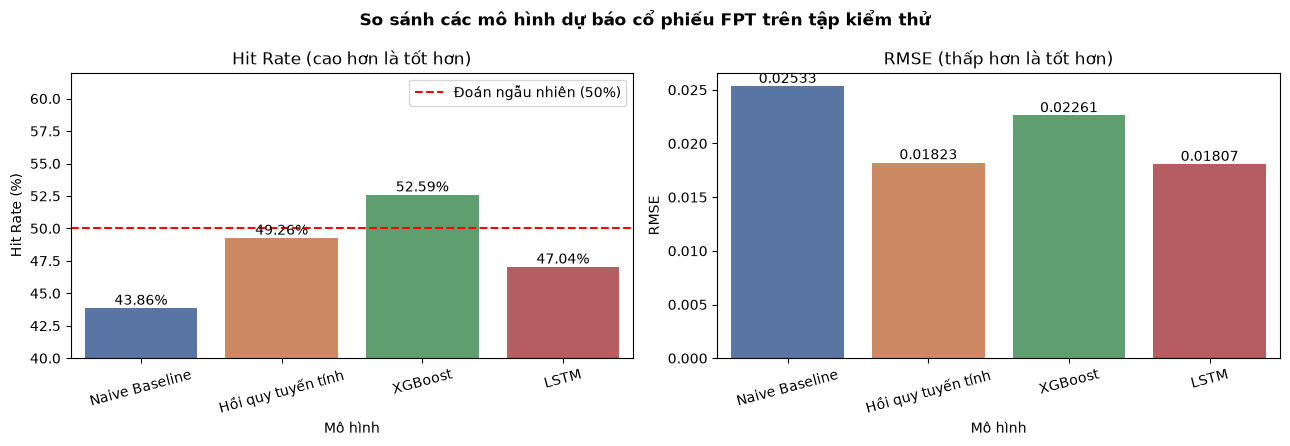

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.barplot(data=result_df, x='Mô hình', y='Hit Rate (%)', hue='Mô hình', palette='deep', legend=False, ax=axes[0])
axes[0].axhline(50, color='red', linestyle='--', label='Đoán ngẫu nhiên (50%)')
axes[0].set_ylim(40, 62)
axes[0].set_title('Hit Rate (cao hơn là tốt hơn)')
axes[0].legend()
for c in axes[0].containers:
    axes[0].bar_label(c, fmt='%.2f%%')
sns.barplot(data=result_df, x='Mô hình', y='RMSE', hue='Mô hình', palette='deep', legend=False, ax=axes[1])
axes[1].set_title('RMSE (thấp hơn là tốt hơn)')
for c in axes[1].containers:
    axes[1].bar_label(c, fmt='%.5f')
for a in axes:
    a.tick_params(axis='x', rotation=15)
plt.suptitle('So sánh các mô hình dự báo cổ phiếu FPT trên tập kiểm thử', fontweight='bold')
plt.tight_layout()
plt.savefig(FIG_DIR / 'fpt_model_benchmark.png', dpi=300)
plt.show()

## 5. Nhận xét

- Hit Rate trên 50% cho thấy mô hình có lợi thế thống kê so với việc đoán ngẫu nhiên; mức 52 đến 55% đã có ý nghĩa trong bài toán tài chính nhiều nhiễu.
- So sánh RMSE và MAE giữa LSTM với Hồi quy tuyến tính, XGBoost cho biết liệu độ phức tạp của học sâu có thực sự mang lại cải thiện.
- Kết quả được ghi trực tiếp từ lần chạy ở trên, không điền tay.